# Student Outcomes and GPA

## Setup

In [1]:
!pip install ucimlrepo

In [2]:
# Libraries used in this notebook
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, mean_squared_error

In [3]:
# Load both datasets once
dataset = fetch_ucirepo(id=697)      # Student dropout and academic success
df_2 = fetch_ucirepo(id=856).data.original   # Higher education student performance

grade_cols = ['Admission grade', 'Curricular units 1st sem (grade)', 'Curricular units 2nd sem (grade)']
gpa_cols = ['Cumulative grade point average in the last semester (/4.00)',
            'Expected Cumulative grade point average in the graduation (/4.00)']

sns.set(style="whitegrid")

# Boxplot each column by outcome, side by side
def outcome_boxplots(data, target, columns, titles, figsize, sharey=False, **box_kw):
    fig, axes = plt.subplots(1, len(columns), figsize=figsize, sharey=sharey)
    for ax, col, title in zip(axes, columns, titles):
        sns.boxplot(data=data, x=target, y=col, ax=ax, **box_kw)
        ax.set_title(title)
    plt.tight_layout()
    plt.show()

# Train a Random Forest on the given features and plot their importance scores
def plot_rf_importance(data, features, target):
    y_enc = LabelEncoder().fit_transform(data[target])
    X_train, X_test, y_train, y_test = train_test_split(data[features], y_enc, test_size=0.3, random_state=42)
    importances = RandomForestClassifier(random_state=42).fit(X_train, y_train).feature_importances_
    plt.figure(figsize=(8, 5))
    plt.barh(features, importances, color='skyblue')
    plt.xlabel("Feature Importance Score")
    plt.title("Which Features Best Predict Student Outcome")
    plt.tight_layout()
    plt.show()

# Fit a linear regression from the two GPA columns to a target and print the RMSE
def gpa_regression_rmse(y, note):
    X_train, X_test, y_train, y_test = train_test_split(df_2[gpa_cols], y, test_size=0.2, random_state=42)
    model = LinearRegression().fit(X_train, y_train)
    rmse = np.sqrt(mean_squared_error(y_test, model.predict(X_test)))
    print("RMSE:", rmse)
    print(f"The model's predictions are about {note} units away from the actual output grade on average.")
    return model

## Dropout Prediction

In [4]:
# Predict dropout with logistic regression and rank the most influential features
X = dataset.data.features
y_binary = (dataset.data.targets['Target'] == 'Dropout').astype(int)   # Dropout = 1, others = 0

# One-hot encode categorical columns (the three grade columns are already numeric features)
X_encoded = pd.get_dummies(X, drop_first=True)
X_scaled = StandardScaler().fit_transform(X_encoded)   # Mean 0, standard deviation 1

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_binary, test_size=0.2, random_state=42)
logreg = LogisticRegression(max_iter=1000).fit(X_train, y_train)

print("Classification Report:")
print(classification_report(y_test, logreg.predict(X_test)))

# Features sorted by the size of their coefficient
coef_df = pd.DataFrame({'Feature': X_encoded.columns, 'Coefficient': logreg.coef_[0]}
                       ).sort_values(by='Coefficient', key=abs, ascending=False)
print("\n Top Influential Features (Logistic Regression Coefficients):")
print(coef_df.head(10))

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.95      0.90       569
           1       0.88      0.72      0.79       316

    accuracy                           0.87       885
   macro avg       0.87      0.83      0.85       885
weighted avg       0.87      0.87      0.86       885


 Top Influential Features (Logistic Regression Coefficients):
                                Feature  Coefficient
30  Curricular units 2nd sem (approved)    -1.866441
28  Curricular units 2nd sem (enrolled)     1.114171
24  Curricular units 1st sem (approved)    -0.976295
16              Tuition fees up to date    -0.762553
27  Curricular units 2nd sem (credited)     0.484580
21  Curricular units 1st sem (credited)     0.420171
19                    Age at enrollment     0.382771
31     Curricular units 2nd sem (grade)    -0.368263
10                  Mother's occupation    -0.336134
25     Curricular units 1st sem (grade)     0.291597


## Grades and Student Outcome

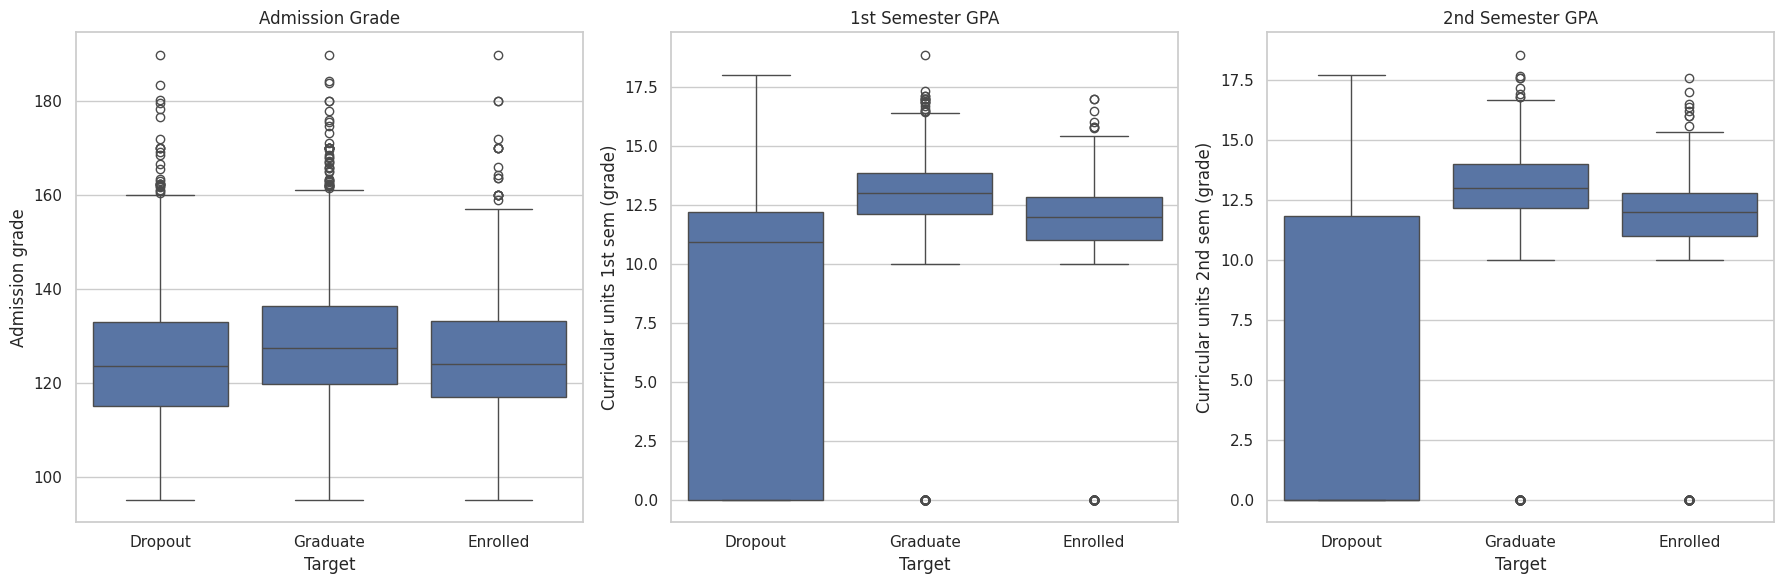

In [5]:
# Admission and semester grades by outcome (Dropout, Enrolled, Graduate)
df = dataset.data.original
df.columns = df.columns.str.strip()
df_filtered = df.dropna(subset=grade_cols + ['Target'])

outcome_boxplots(df_filtered, 'Target', grade_cols,
                 ['Admission Grade', '1st Semester GPA', '2nd Semester GPA'], figsize=(18, 6))

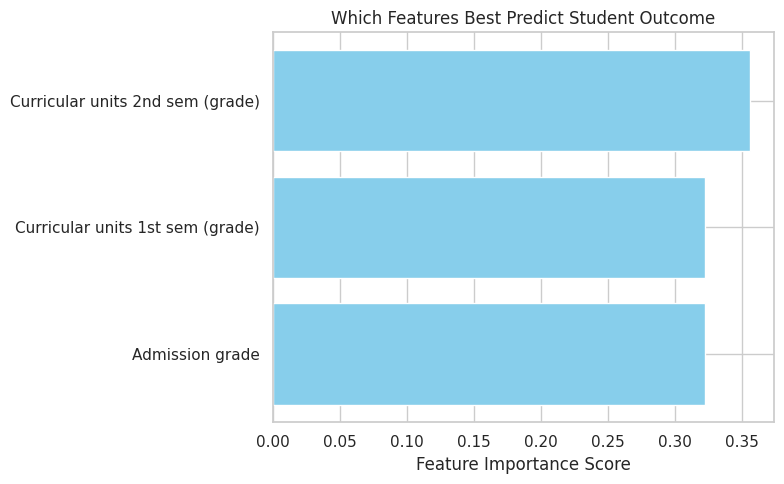

In [6]:
# Which grade best predicts student outcome (Random Forest feature importance)
# feature_importances_ shows how important each feature is in predicting the outcome
plot_rf_importance(df_filtered, grade_cols, 'Target')

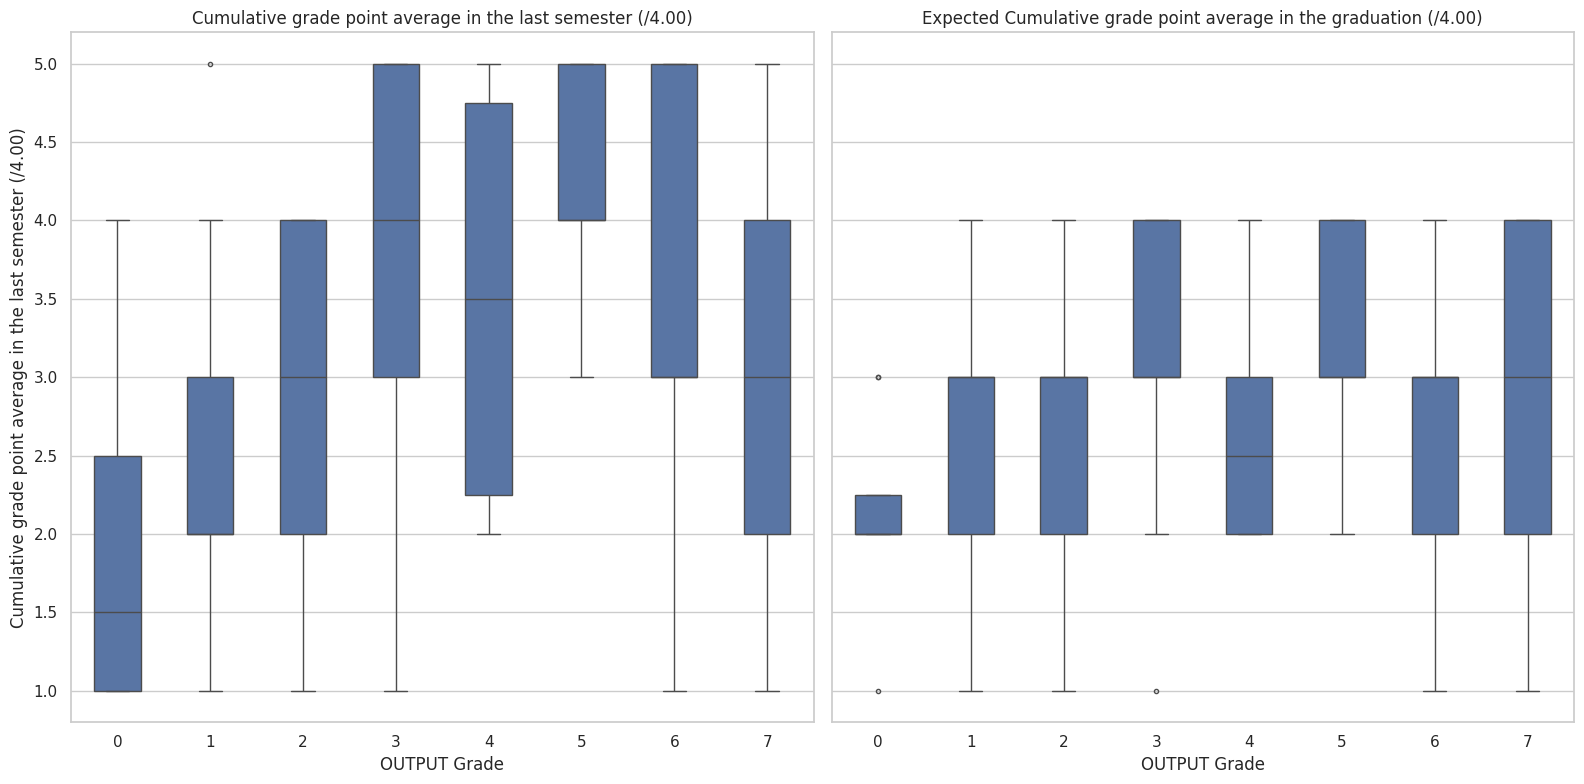

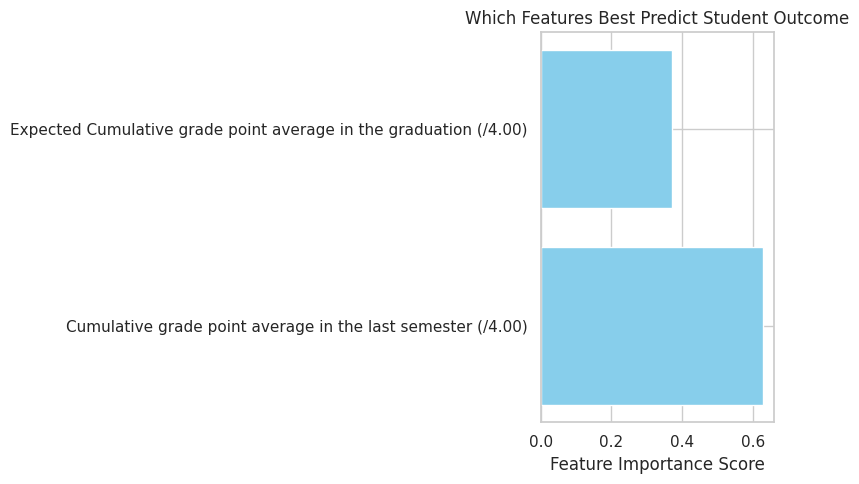

In [7]:
# GPA by output grade in the second dataset, then the Random Forest feature importance scores
df_filtered_2 = df_2.dropna(subset=gpa_cols + ['OUTPUT Grade'])

outcome_boxplots(df_filtered_2, 'OUTPUT Grade', gpa_cols, gpa_cols, figsize=(16, 8),
                 sharey=True, width=0.5, fliersize=3)
plot_rf_importance(df_filtered_2, gpa_cols, 'OUTPUT Grade')

## Predicting Output Grade from GPA

In [8]:
# Linear regression on the raw output grade (0-7)
gpa_regression_rmse(df_2['OUTPUT Grade'], "2.08");

RMSE: 2.077135436034905
The model's predictions are about 2.08 units away from the actual output grade on average.


In [9]:
# Map output grade (0-7) to a 1-5 scale - a less accurate method
to_5_levels = {0: 1, 1: 1, 2: 2, 3: 2, 4: 3, 5: 4, 6: 5, 7: 5}
gpa_regression_rmse(df_2['OUTPUT Grade'].map(to_5_levels), "1.42");

RMSE: 1.4164594883885404
The model's predictions are about 1.42 units away from the actual output grade on average.


In [10]:
# Map output grade to a 4.0 GPA scale - a better method with lower RMSE
# RMSE measures the average size of the errors between predicted and actual values
to_gpa = {0: 0.0, 1: 1.0, 2: 1.5, 3: 2.0, 4: 2.5, 5: 3.0, 6: 3.5, 7: 4.0}
model = gpa_regression_rmse(df_2['OUTPUT Grade'].map(to_gpa), "1.16")

RMSE: 1.156084453922634
The model's predictions are about 1.16 units away from the actual output grade on average.


In [11]:
# Intercept and coefficients of the 4.0 GPA scale model
print("Intercept:", model.intercept_)
for feature, coef in zip(gpa_cols, model.coef_):
    print(f"Coefficient for {feature}: {coef:.4f}")

print("\nThe coefficients indicate the change in the output grade for a one-unit increase in each feature, holding other features constant.")
# For example, a coefficient of 0.3 for last-semester GPA means each additional GPA point raises the
# predicted output grade by 0.3, with the other feature held constant.

Intercept: 1.2229976745904954
Coefficient for Cumulative grade point average in the last semester (/4.00): 0.3023
Coefficient for Expected Cumulative grade point average in the graduation (/4.00): -0.0216

The coefficients indicate the change in the output grade for a one-unit increase in each feature, holding other features constant.
